# Lab 4 | Adaptive Optimizers for a CNN (Fashion-MNIST)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/24pwai0015-max/ann-and-deep-learning/blob/main/labs/Lab4_Adaptive_Optimizers_CNN.ipynb)

**Course:** Deep Learning Foundations | Practical Labs  
**Author:** Arsalan

This notebook builds one compact **CNN** and trains it five times on the same Fashion-MNIST subset (2400 train / 500 validation / 1000 test), starting from identical weights, changing only the optimizer: SGD, Adam, RMSprop, Adadelta and Adagrad.

> **How to run:** In Google Colab choose *Runtime → Run all*. Keras downloads the public dataset on first use.
> Numbers (especially *seconds*) can differ slightly between machines, so always report values from **your own** run.


## 1. Settings and data preparation

In [1]:
# LAB 4: Compare SGD, Adam, RMSprop, Adadelta and Adagrad in a CNN.
# Run in Google Colab or locally after: pip install tensorflow numpy matplotlib
# Dataset: Fashion-MNIST, a public 10-class clothing image dataset.

import os  # Control TensorFlow's informational messages.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # Hide routine start-up logs.
import csv  # Save measured outcomes to a portable CSV file.
import time  # Measure the actual training time for each optimizer.
from pathlib import Path  # Save charts and tables in one folder.
import numpy as np  # Select deterministic dataset subsets.
import matplotlib.pyplot as plt  # Plot validation accuracy histories.
import tensorflow as tf  # Use Keras to implement a convolutional model.

SEED = 42  # Keep the dataset split and the weight initialization repeatable.
TRAIN_N = 2400  # Use a smaller dataset for an affordable classroom lab.
VAL_N = 500  # Reserve these images for validation during the comparison.
TEST_N = 1000  # Hold out separate examples for testing.
EPOCHS = 4  # Use an identical number of training epochs in all runs.
BATCH_SIZE = 64  # Keep the batch size constant when changing optimizers.
OUT = Path("lab4_cnn_optimizer_results")  # Set the output folder name.
OUT.mkdir(parents=True, exist_ok=True)  # Ensure the folder exists.
tf.keras.utils.set_random_seed(SEED)  # Seed Python, NumPy and TensorFlow.

(x_all, y_all), (x_test_all, y_test_all) = tf.keras.datasets.fashion_mnist.load_data()  # Load Fashion-MNIST.
rng = np.random.default_rng(SEED)  # Prepare a reproducible random selector.
train_ids = rng.permutation(len(x_all))[:TRAIN_N + VAL_N]  # Select training and validation images.
test_ids = rng.permutation(len(x_test_all))[:TEST_N]  # Select test images from the official test set.
x_train = x_all[train_ids[:TRAIN_N]].astype("float32") / 255.0  # Scale training image pixels to 0..1.
y_train = y_all[train_ids[:TRAIN_N]]  # Keep the matching training labels.
x_val = x_all[train_ids[TRAIN_N:]].astype("float32") / 255.0  # Scale validation pixels to 0..1.
y_val = y_all[train_ids[TRAIN_N:]]  # Keep the matching validation labels.
x_test = x_test_all[test_ids].astype("float32") / 255.0  # Scale held-out test pixels to 0..1.
y_test = y_test_all[test_ids]  # Keep the matching test labels.
x_train = x_train[..., np.newaxis]  # Add the required grayscale CNN channel dimension.
x_val = x_val[..., np.newaxis]  # Give validation data the shape (N, 28, 28, 1).
x_test = x_test[..., np.newaxis]  # Give test data the same image shape.
print("Train:", x_train.shape, "| Validation:", x_val.shape, "| Test:", x_test.shape)  # Confirm shapes.


Train: (2400, 28, 28, 1) | Validation: (500, 28, 28, 1) | Test: (1000, 28, 28, 1)


## 2. CNN definition and the five optimizers

In [2]:
def build_cnn():  # Build a compact image classifier used for all five optimizers.
    return tf.keras.Sequential([  # Create a sequential convolutional network.
        tf.keras.layers.Input(shape=(28, 28, 1)),  # Expect 28-by-28 grayscale images.
        tf.keras.layers.Conv2D(16, 3, activation="relu"),  # Detect low-level visual patterns.
        tf.keras.layers.MaxPooling2D(),  # Shrink the feature maps to reduce calculations.
        tf.keras.layers.Conv2D(32, 3, activation="relu"),  # Learn more complex image features.
        tf.keras.layers.MaxPooling2D(),  # Compress the second group of maps.
        tf.keras.layers.Flatten(),  # Convert the feature maps into one vector.
        tf.keras.layers.Dense(32, activation="relu"),  # Combine the extracted visual features.
        tf.keras.layers.Dense(10, activation="softmax"),  # Return probabilities for 10 clothing classes.
    ])  # Complete the CNN architecture.

# Students can manually replace the one optimizer expression in model.compile.
# These explicit rates are teaching starting points, not universal defaults.
OPTIMIZERS = [  # Declare five independent optimizer configurations.
    ("SGD", lambda: tf.keras.optimizers.SGD(learning_rate=0.01)),  # Non-adaptive baseline.
    ("Adam", lambda: tf.keras.optimizers.Adam(learning_rate=0.001)),  # Moment estimates.
    ("RMSprop", lambda: tf.keras.optimizers.RMSprop(learning_rate=0.001)),  # Moving squared gradients.
    ("Adadelta", lambda: tf.keras.optimizers.Adadelta(learning_rate=1.0)),  # Windowed update scales.
    ("Adagrad", lambda: tf.keras.optimizers.Adagrad(learning_rate=0.01)),  # Accumulated squared gradients.
]  # Finish the comparison group.


## 3. Training loop (identical initial weights for every optimizer)

In [3]:
tf.keras.utils.set_random_seed(SEED)  # Control the initialization of the reference network.
reference_model = build_cnn()  # Create an untrained CNN with known starting weights.
initial_weights = reference_model.get_weights()  # Save an identical start for every optimizer.
del reference_model  # Discard this model without training it.
results = []  # Prepare rows for the measured results table.
histories = {}  # Prepare the validation accuracy trajectories for plotting.
epoch_rows = []  # Prepare per-epoch rows so convergence speed can be inspected.
for opt_name, make_optimizer in OPTIMIZERS:  # Compare one optimizer at a time.
    tf.keras.utils.set_random_seed(SEED)  # Reapply the seeds at the start of each run.
    model = build_cnn()  # Rebuild the same CNN architecture.
    model.set_weights(initial_weights)  # Reset the model to the same initial weights.
    optimizer = make_optimizer()  # Select the optimizer under comparison.
    model.compile(optimizer=optimizer,  # Attach the optimizer under test.
                  loss="sparse_categorical_crossentropy",  # Use the integer-label loss.
                  metrics=["accuracy"])  # Track classification accuracy.
    start = time.perf_counter()  # Note the start time directly before training.
    history = model.fit(x_train, y_train,  # Train on the fixed training subset.
                        validation_data=(x_val, y_val),  # Validate after every epoch.
                        epochs=EPOCHS,  # Use the same number of epochs every time.
                        batch_size=BATCH_SIZE,  # Use the same batch size every time.
                        shuffle=True,  # Shuffle the training data each epoch.
                        verbose=0)  # Train without verbose progress logs.
    elapsed = time.perf_counter() - start  # Record the training time on this machine.
    test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)  # Assess held-out examples.
    best_val = max(history.history["val_accuracy"])  # Find the best validation epoch.
    histories[opt_name] = history.history["val_accuracy"]  # Store the epoch-by-epoch curve.
    results.append({  # Record the observed scores as one table row.
        "optimizer": opt_name,  # Optimizer name.
        "learning_rate": round(float(optimizer.learning_rate.numpy()), 6),  # Learning rate used.
        "best_val_accuracy": round(best_val, 4),  # Best validation accuracy over the epochs.
        "test_accuracy": round(test_accuracy, 4),  # Accuracy on the held-out test subset.
        "test_loss": round(test_loss, 4),  # Loss on the held-out test subset.
        "train_seconds": round(elapsed, 2),  # Training time on this machine.
    })  # Finish the result row.
    for epoch_no, acc in enumerate(history.history["val_accuracy"], start=1):  # Walk through epochs.
        epoch_rows.append({"optimizer": opt_name, "epoch": epoch_no,  # Identify the run and epoch.
                           "val_accuracy": round(acc, 4)})  # Save its validation accuracy.
    print(f"{opt_name:8} | val={best_val:.3f} | test={test_accuracy:.3f} | time={elapsed:.1f}s")  # Print outcomes.


SGD      | val=0.370 | test=0.378 | time=2.3s


Adam     | val=0.726 | test=0.711 | time=3.4s


RMSprop  | val=0.704 | test=0.694 | time=2.3s


Adadelta | val=0.730 | test=0.729 | time=2.4s


Adagrad  | val=0.522 | test=0.516 | time=3.8s


## 4. Plot the validation curves and save the measured results as CSV

In [4]:
plt.figure(figsize=(8, 4.5))  # Create one validation accuracy comparison figure.
for name, accuracy_curve in histories.items():  # Plot each optimizer history.
    plt.plot(range(1, EPOCHS + 1), accuracy_curve, marker="o", label=name)  # Draw actual validation values.
plt.title("CNN on Fashion-MNIST: optimizer comparison")  # Label the comparison context.
plt.xlabel("Epoch")  # Show epochs horizontally.
plt.ylabel("Validation accuracy")  # Show held-out validation performance vertically.
plt.xticks(range(1, EPOCHS + 1))  # Display one tick per training epoch.
plt.grid(alpha=0.25)  # Add a light grid for reading trends.
plt.legend()  # Display the five optimizer names.
plt.tight_layout()  # Avoid clipped graph labels.
plt.savefig(OUT / "cnn_validation_accuracy.png", dpi=160)  # Export the observed curves.
plt.close()  # Free the matplotlib figure.
with (OUT / "cnn_optimizer_results.csv").open("w", newline="", encoding="utf-8") as file:  # Open the CSV.
    writer = csv.DictWriter(file, fieldnames=list(results[0].keys()))  # Set stable output headings.
    writer.writeheader()  # Export the column names first.
    writer.writerows(results)  # Export the five measured experiments.
with (OUT / "epoch_validation_accuracy.csv").open("w", newline="", encoding="utf-8") as file:  # Second CSV.
    writer = csv.DictWriter(file, fieldnames=list(epoch_rows[0].keys()))  # Columns for the epoch table.
    writer.writeheader()  # Write the column names.
    writer.writerows(epoch_rows)  # Write the per-epoch validation accuracies.
print(f"Results and plot saved to: {OUT.resolve()}")  # Tell the reader where the files are located.


Results and plot saved to: /home/claude/work/lab4/lab4_cnn_optimizer_results


## Results: measured table and graphs
The cell below only *reads back* the files written above.

Measured results (cnn_optimizer_results.csv):


,optimizer,learning_rate,best_val_accuracy,test_accuracy,test_loss,train_seconds
0,SGD,0.010,0.370,0.378,1.8289,2.28
1,Adam,0.001,0.726,0.711,0.7331,3.38
2,RMSprop,0.001,0.704,0.694,0.8340,2.30
3,Adadelta,1.000,0.730,0.729,0.7314,2.44
4,Adagrad,0.010,0.522,0.516,1.1765,3.75


Validation accuracy per epoch:


epoch,1,2,3,4
optimizer,,,,
Adadelta,0.460,0.574,0.698,0.730
Adagrad,0.344,0.490,0.492,0.522
Adam,0.576,0.666,0.704,0.726
RMSprop,0.530,0.632,0.690,0.704
SGD,0.252,0.278,0.332,0.370


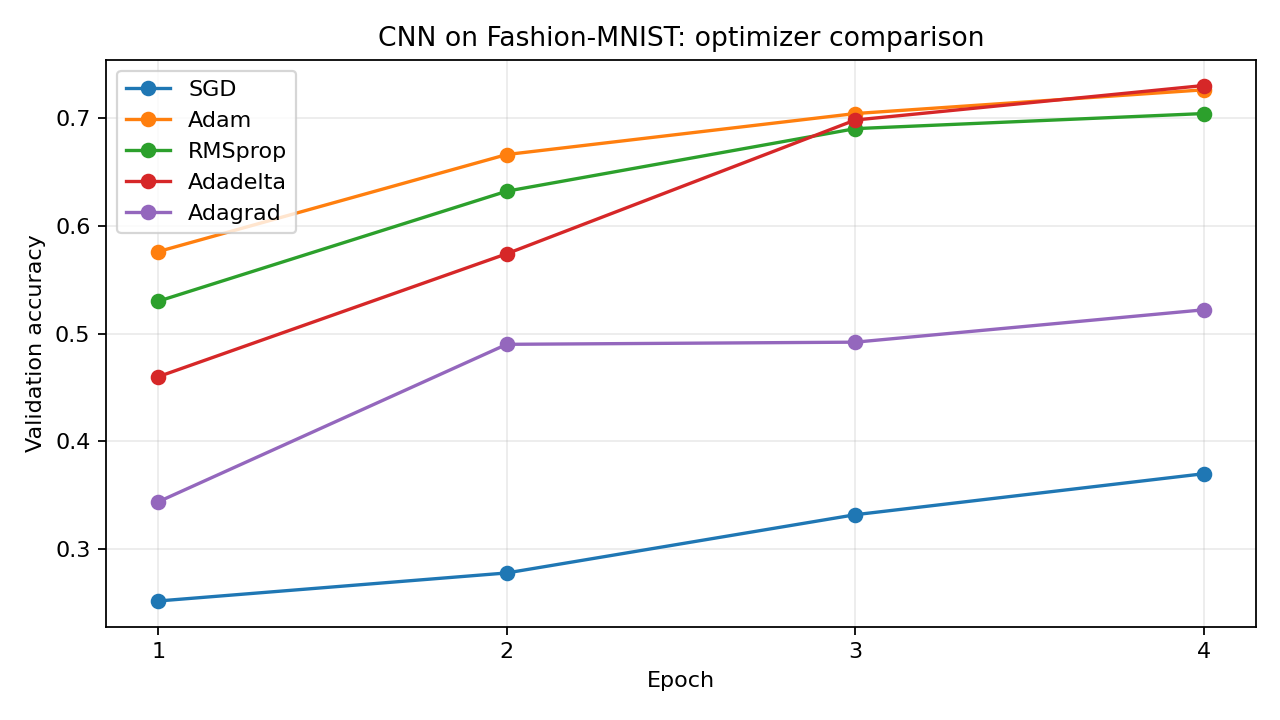

In [5]:
import pandas as pd  # Read the CSV files back as tables.
from IPython.display import Image, display  # Show the saved graph inside the notebook.
print("Measured results (cnn_optimizer_results.csv):")  # Introduce the main table.
display(pd.read_csv(OUT / "cnn_optimizer_results.csv"))  # Show the real measured table.
print("Validation accuracy per epoch:")  # Introduce the convergence table.
display(pd.read_csv(OUT / "epoch_validation_accuracy.csv")  # Load the per-epoch values.
        .pivot_table(index="optimizer", columns="epoch", values="val_accuracy"))  # One row per optimizer.
display(Image(filename=str(OUT / "cnn_validation_accuracy.png")))  # Display the saved PNG graph.


## Discussion

Adam appears to converge fastest on this CNN: after epoch 1 it already reached 0.576 validation accuracy, ahead of RMSprop (0.530), Adadelta (0.460), Adagrad (0.344) and SGD (0.252). Adadelta started slower but climbed steeply and finished with the highest best validation accuracy (0.730) and test accuracy (0.729), just ahead of Adam (0.726 and 0.711). The fastest starter was therefore not the best finisher, and after only four epochs none of the networks has converged. Accuracy and computation time answer different questions: accuracy measures how well the trained model predicts unseen images, while seconds measure the cost of training. The times here (2.3 to 3.8 s) do not follow accuracy; Adagrad was slowest at 3.75 s yet reached only 0.522. Such short single runs are noisy, so a one-second gap should not be read as a property of the optimizer. A Conv2D layer expects four-dimensional input (batch, height, width, channels). Fashion-MNIST images are 28 x 28, so a channel axis of size 1 must be added to obtain (N, 28, 28, 1).

### What changed, what stayed fixed, limitations
- **Changed:** only the optimizer object (SGD, Adam, RMSprop, Adadelta, Adagrad) and its learning rate.
- **Fixed:** CNN architecture, image subsets and scaling, seed, identical starting weights, loss, EPOCHS = 4 and BATCH_SIZE = 64.
- **Limitations:** one seed per optimizer, only four epochs (no model has converged; absolute accuracies are low), 500 validation images, learning rates not tuned, and training seconds measured once on a CPU, so small time differences are noise.

### Interpretation
**Which optimizer improves fastest?** Adam had the highest validation accuracy after epochs 1 and 2 (0.576 and 0.666); Adadelta gained the most overall (0.460 to 0.730) and was still rising steeply at epoch 4.

**Does the fastest mean the best?** No. Adam led early, but Adadelta finished with the best validation and test accuracy. With so few epochs and one seed, the gap between the two (0.4 percentage points on validation) is within noise.

**Why did we reset weights?** Restoring identical initial weights before every run removes the starting point as a variable; otherwise a lucky or unlucky initialization could be mistaken for an optimizer effect.

**How to make a stronger study?** Repeat each optimizer with several seeds and report mean and spread, tune each learning rate separately, train for more epochs (or until early stopping), and use the full dataset.

*Numbers above come from the run stored in this notebook; re-running (e.g. in Colab) may change seconds and slightly change accuracies.*